# 02 Exploratory data analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_csv('../data/processed/countries_2019.csv')
names = ['GDP_PC', 'GDP_GROWTH', 'INFLATION', 'UNEMPLOYMENT', 'TRADE', 'CAPITAL_FORMATION',
         'LIFE_EXPECTANCY', 'URBAN_POP', 'INTERNET_USERS', 'ELECTRICITY_ACCESS', 'SECONDARY_ENROLLMENT']
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
short = {'Low income': 'Low', 'Lower middle income': 'Lower-mid', 'Upper middle income': 'Upper-mid', 'High income': 'High'}
df['income'] = df['income_group'].map(short)

## 1. Inspect the dataset

In [3]:
print(df.shape)
df.info()

(186, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186 entries, 0 to 185
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   country               186 non-null    object 
 1   code                  186 non-null    object 
 2   region                186 non-null    object 
 3   income_group          186 non-null    object 
 4   lending_type          186 non-null    object 
 5   GDP_PC                186 non-null    float64
 6   GDP_GROWTH            186 non-null    float64
 7   INFLATION             178 non-null    float64
 8   UNEMPLOYMENT          178 non-null    float64
 9   TRADE                 173 non-null    float64
 10  CAPITAL_FORMATION     172 non-null    float64
 11  LIFE_EXPECTANCY       186 non-null    float64
 12  URBAN_POP             186 non-null    float64
 13  INTERNET_USERS        183 non-null    float64
 14  ELECTRICITY_ACCESS    186 non-null    float64
 15  SECONDARY_ENR

In [4]:
print(df[names].isnull().sum())

GDP_PC                   0
GDP_GROWTH               0
INFLATION                8
UNEMPLOYMENT             8
TRADE                   13
CAPITAL_FORMATION       14
LIFE_EXPECTANCY          0
URBAN_POP                0
INTERNET_USERS           3
ELECTRICITY_ACCESS       0
SECONDARY_ENROLLMENT    24
dtype: int64


In [5]:
df[names].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
GDP_PC,186.0,15488.77,20401.46,234.31,2185.06,6188.34,19388.38,112696.65
GDP_GROWTH,186.0,2.66,4.05,-27.62,1.22,2.65,4.86,24.21
INFLATION,178.0,5.30,20.14,-3.23,0.84,2.24,3.73,255.30
UNEMPLOYMENT,178.0,7.23,5.71,0.10,3.39,5.08,9.87,28.47
TRADE,173.0,90.22,58.84,22.82,53.90,76.12,108.21,382.66
CAPITAL_FORMATION,172.0,24.51,8.54,2.28,19.30,23.11,27.60,53.70
LIFE_EXPECTANCY,186.0,72.70,8.10,31.53,66.80,73.84,78.29,85.26
URBAN_POP,186.0,60.77,22.44,13.93,42.75,62.50,78.31,100.00
INTERNET_USERS,183.0,59.92,27.35,2.73,36.54,67.95,82.32,99.70
ELECTRICITY_ACCESS,186.0,85.35,24.90,8.40,83.35,99.80,100.00,100.00


In [6]:
def skewness(x):
    x = x.dropna()
    return ((x - x.mean()) ** 3).mean() / x.std() ** 3

summary = pd.DataFrame()
for name in names:
    summary.loc[name, 'mean'] = df[name].mean()
    summary.loc[name, 'median'] = df[name].median()
    summary.loc[name, 'max / min'] = df[name].max() / df[name].min()
    summary.loc[name, 'skewness'] = skewness(df[name])
summary.round(2)

,mean,median,max / min,skewness
GDP_PC,15488.77,6188.34,480.97,1.97
GDP_GROWTH,2.66,2.65,-0.88,-1.74
INFLATION,5.30,2.24,-78.96,10.93
UNEMPLOYMENT,7.23,5.08,284.68,1.48
TRADE,90.22,76.12,16.77,2.43
CAPITAL_FORMATION,24.51,23.11,23.54,0.75
LIFE_EXPECTANCY,72.70,73.84,2.70,-0.96
URBAN_POP,60.77,62.50,7.18,-0.20
INTERNET_USERS,59.92,67.95,36.50,-0.44
ELECTRICITY_ACCESS,85.35,99.80,11.90,-1.61


### Extreme observations (IQR rule)

In [7]:
def detect_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
    return outliers

for name in names:
    outliers = detect_outliers_iqr(df, name)
    print(f'{name}: {len(outliers)} outliers')

GDP_PC: 21 outliers
GDP_GROWTH: 7 outliers
INFLATION: 19 outliers
UNEMPLOYMENT: 8 outliers
TRADE: 7 outliers
CAPITAL_FORMATION: 14 outliers
LIFE_EXPECTANCY: 1 outliers
URBAN_POP: 0 outliers
INTERNET_USERS: 0 outliers


ELECTRICITY_ACCESS: 32 outliers
SECONDARY_ENROLLMENT: 4 outliers


In [8]:
for name in names:
    ordered = df.dropna(subset=[name]).sort_values(name)
    print(name)
    print('   lowest :', list(ordered['country'].head(2)), list(ordered[name].head(2).round(1)))
    print('   highest:', list(ordered['country'].tail(2)), list(ordered[name].tail(2).round(1)))

GDP_PC
   lowest : ['Burundi', 'Central African Republic'] [234.3, 449.2]
   highest: ['Switzerland', 'Luxembourg'] [85873.0, 112696.6]
GDP_GROWTH
   lowest : ['Venezuela, RB', 'Libya'] [-27.6, -11.2]
   highest: ['Marshall Islands', 'Timor-Leste'] [10.5, 24.2]
INFLATION
   lowest : ['Burkina Faso', 'Niger'] [-3.2, -2.5]
   highest: ['Argentina', 'Zimbabwe'] [53.5, 255.3]
UNEMPLOYMENT
   lowest : ['Qatar', 'Cambodia'] [0.1, 0.1]
   highest: ['Eswatini', 'South Africa'] [28.2, 28.5]
TRADE
   lowest : ['Cuba', 'Sudan'] [22.8, 26.1]
   highest: ['Hong Kong SAR, China', 'Luxembourg'] [353.7, 382.7]
CAPITAL_FORMATION
   lowest : ['Djibouti', 'Zimbabwe'] [2.3, 6.6]
   highest: ['Marshall Islands', 'Ireland'] [53.2, 53.7]
LIFE_EXPECTANCY
   lowest : ['Central African Republic', 'Chad'] [31.5, 53.0]
   highest: ['Hong Kong SAR, China', 'San Marino'] [85.2, 85.3]
URBAN_POP
   lowest : ['Papua New Guinea', 'Malawi'] [13.9, 16.1]
   highest: ['Macao SAR, China', 'Singapore'] [100.0, 100.0]
INTERN

## 2. Feature distributions

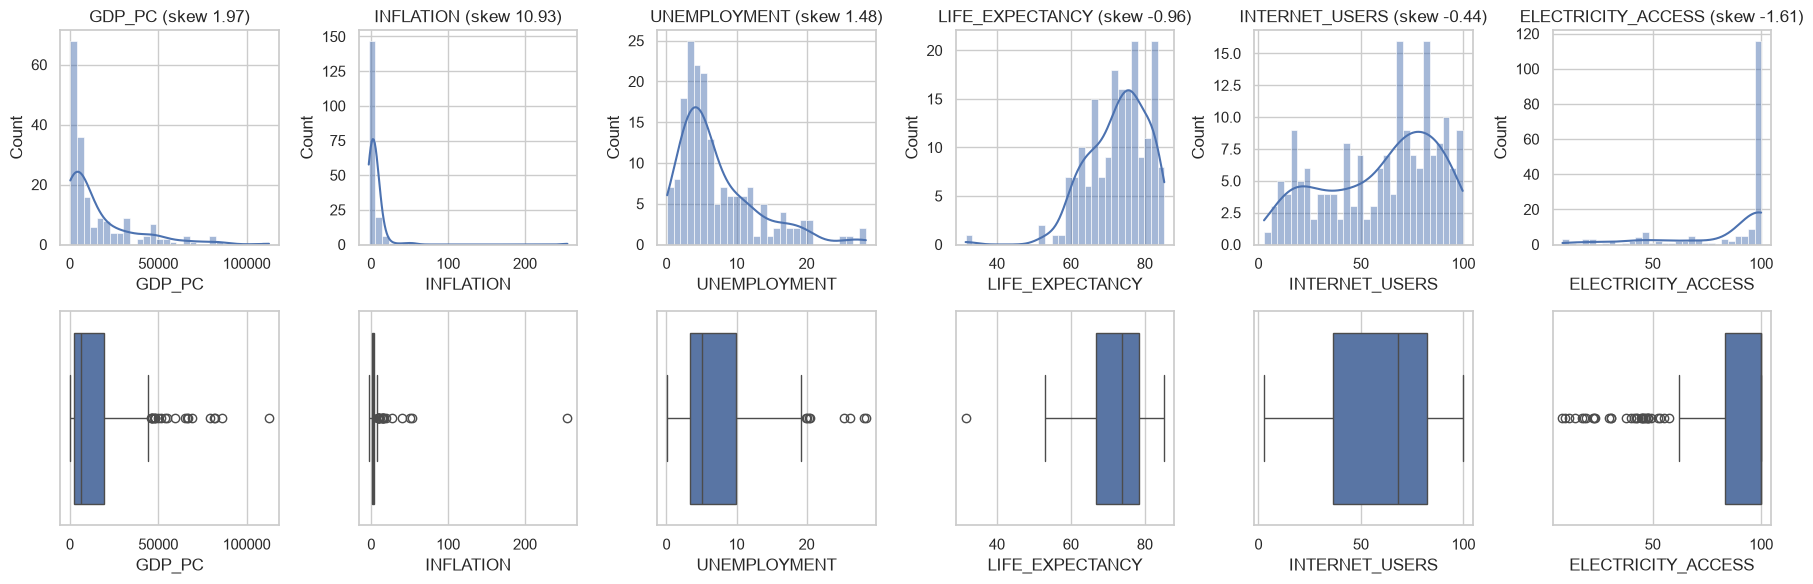

In [9]:
key = ['GDP_PC', 'INFLATION', 'UNEMPLOYMENT', 'LIFE_EXPECTANCY', 'INTERNET_USERS', 'ELECTRICITY_ACCESS']
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for i in range(6):
    sns.histplot(df[key[i]], kde=True, bins=30, ax=axes[0, i])
    axes[0, i].set_title(f'{key[i]} (skew {skewness(df[key[i]]):.2f})')
    sns.boxplot(x=df[key[i]], ax=axes[1, i])
plt.tight_layout()
plt.savefig('../figures/02_distributions.png', dpi=200)
plt.show()

### Log transform of GDP per capita

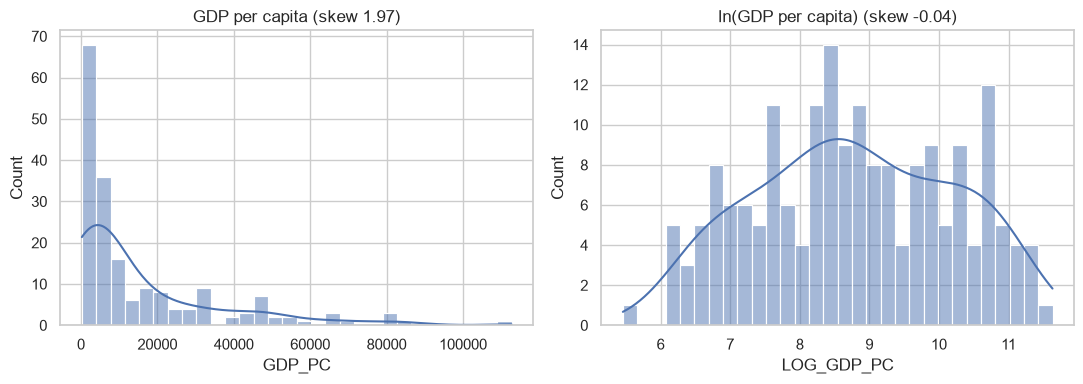

In [10]:
df['LOG_GDP_PC'] = np.log(df['GDP_PC'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['GDP_PC'], kde=True, bins=30, ax=axes[0])
axes[0].set_title(f'GDP per capita (skew {skewness(df["GDP_PC"]):.2f})')
sns.histplot(df['LOG_GDP_PC'], kde=True, bins=30, ax=axes[1])
axes[1].set_title(f'ln(GDP per capita) (skew {skewness(df["LOG_GDP_PC"]):.2f})')
plt.tight_layout()
plt.savefig('../figures/02_log_gdp.png', dpi=200)
plt.show()

## 3. Income groups

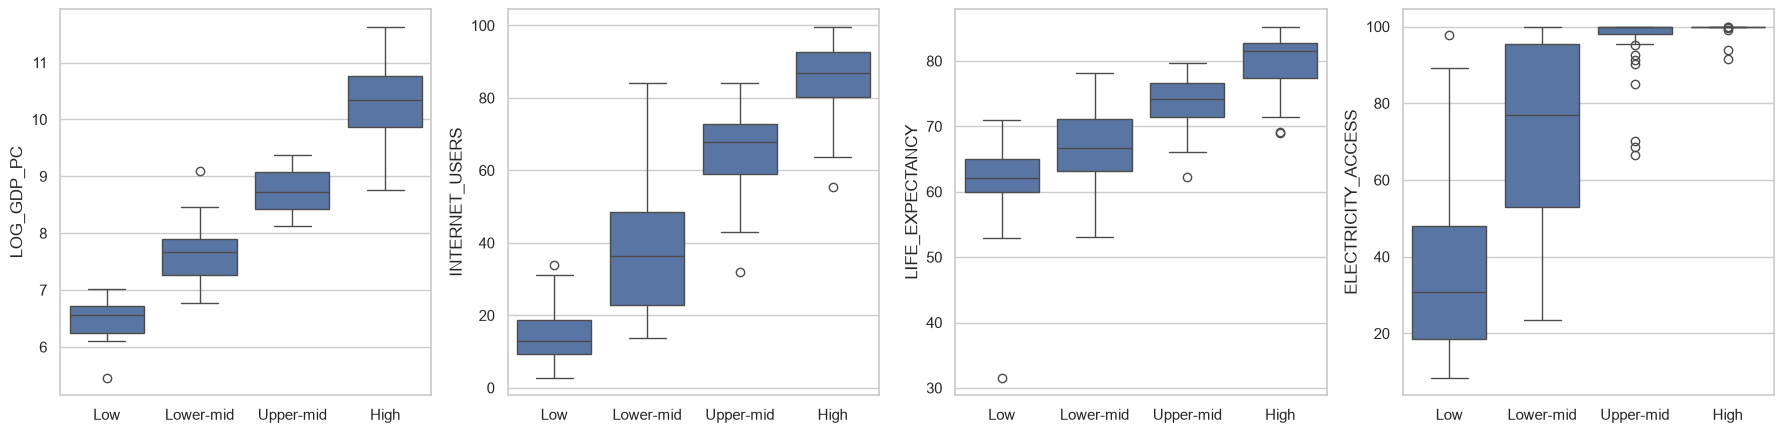

In [11]:
compare = ['LOG_GDP_PC', 'INTERNET_USERS', 'LIFE_EXPECTANCY', 'ELECTRICITY_ACCESS']
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for i in range(4):
    sns.boxplot(data=df, x='income', y=compare[i], order=['Low', 'Lower-mid', 'Upper-mid', 'High'], ax=axes[i])
    axes[i].set_xlabel('')
plt.tight_layout()
plt.savefig('../figures/02_income_groups.png', dpi=200)
plt.show()

In [12]:
df.groupby('income_group')[names].median().T.round(1)

income_group,High income,Low income,Lower middle income,Upper middle income
GDP_PC,31181.2,710.0,2129.8,6188.3
GDP_GROWTH,2.1,5.0,3.5,2.9
INFLATION,1.6,2.9,3.7,2.1
UNEMPLOYMENT,4.8,4.5,5.4,7.9
TRADE,101.4,48.9,67.6,81.0
CAPITAL_FORMATION,23.3,22.7,22.7,24.4
LIFE_EXPECTANCY,81.4,62.2,66.7,74.2
URBAN_POP,79.6,30.3,48.0,64.2
INTERNET_USERS,86.8,13.0,36.4,68.0
ELECTRICITY_ACCESS,100.0,30.9,77.0,99.8


## 4. Correlations

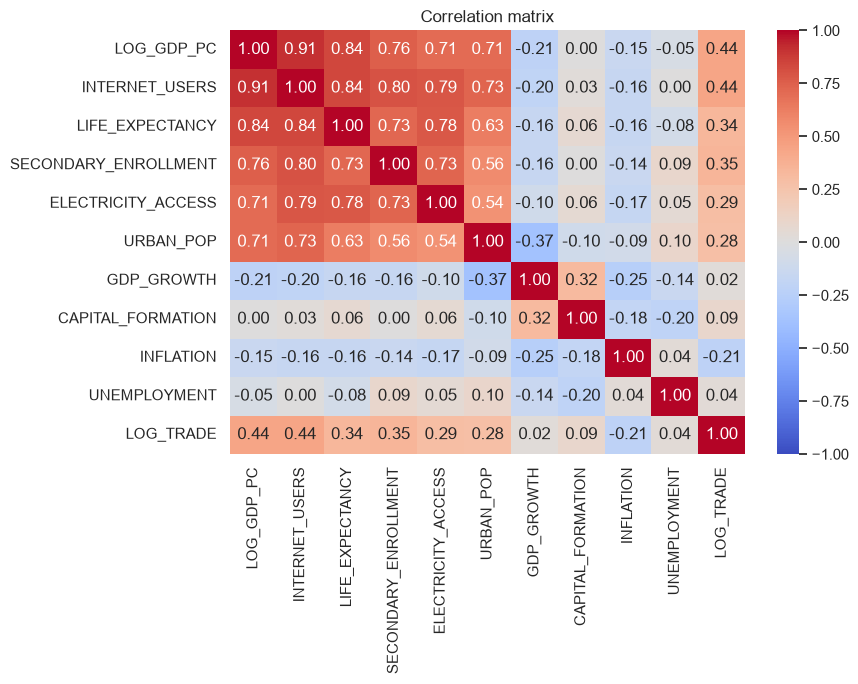

In [13]:
df['LOG_TRADE'] = np.log(df['TRADE'])
corr_names = ['LOG_GDP_PC', 'INTERNET_USERS', 'LIFE_EXPECTANCY', 'SECONDARY_ENROLLMENT', 'ELECTRICITY_ACCESS', 'URBAN_POP',
              'GDP_GROWTH', 'CAPITAL_FORMATION', 'INFLATION', 'UNEMPLOYMENT', 'LOG_TRADE']
corr_matrix = df[corr_names].corr(method='pearson')
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.tight_layout()
plt.savefig('../figures/02_correlation.png', dpi=200)
plt.show()

### Variance inflation factor

In [14]:
complete = df[corr_names].dropna()
for name in corr_names:
    others = complete.drop(columns=[name])
    model = LinearRegression()
    model.fit(others, complete[name])
    r2 = model.score(others, complete[name])
    print(f'{name}: VIF = {1 / (1 - r2):.2f}')

LOG_GDP_PC: VIF = 9.62
INTERNET_USERS: VIF = 9.58
LIFE_EXPECTANCY: VIF = 5.57
SECONDARY_ENROLLMENT: VIF = 3.70
ELECTRICITY_ACCESS: VIF = 3.50
URBAN_POP: VIF = 3.39
GDP_GROWTH: VIF = 1.55
CAPITAL_FORMATION: VIF = 1.19
INFLATION: VIF = 1.32
UNEMPLOYMENT: VIF = 1.17
LOG_TRADE: VIF = 1.47


## 5. Pairwise relationships

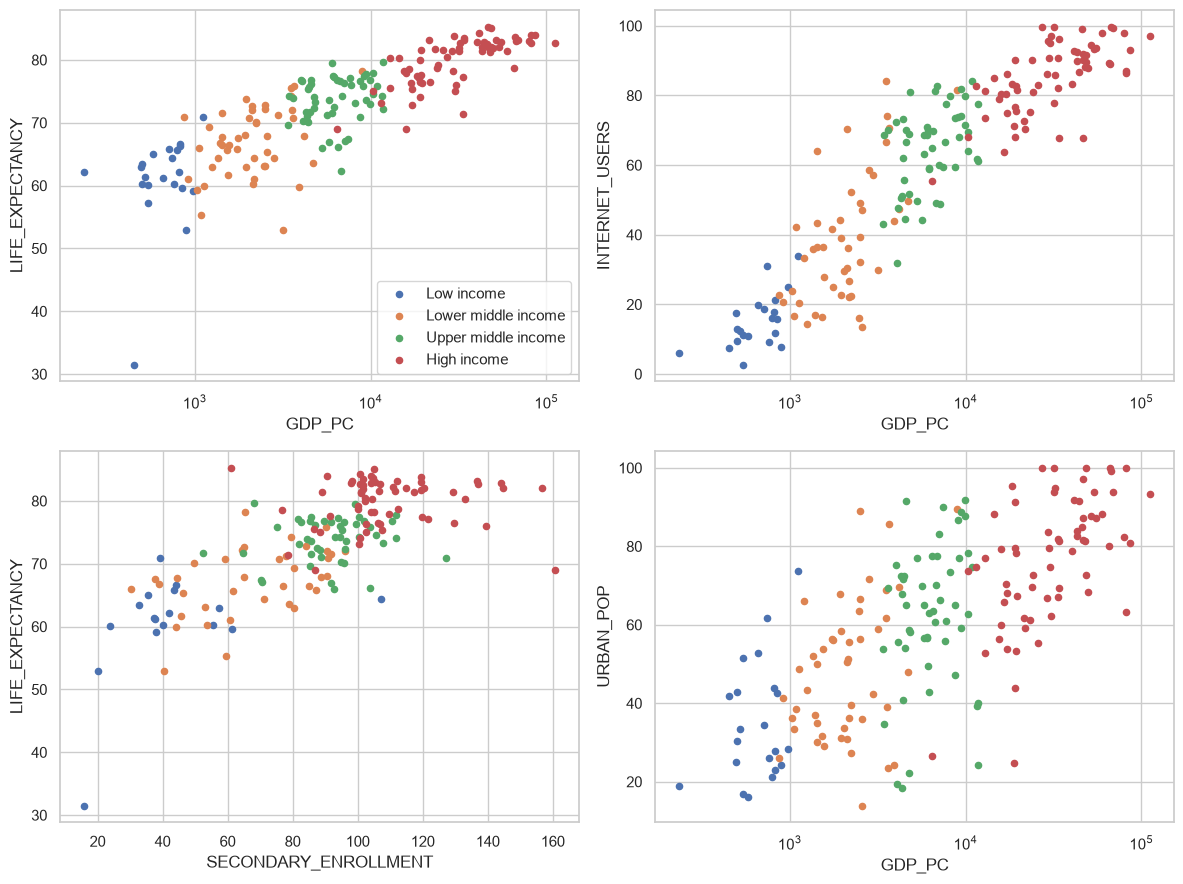

In [15]:
def scatter_by_income(ax, x, y):
    for group in income_order:
        part = df[df['income_group'] == group]
        ax.scatter(part[x], part[y], s=20, label=group)
    ax.set_xlabel(x)
    ax.set_ylabel(y)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
scatter_by_income(axes[0, 0], 'GDP_PC', 'LIFE_EXPECTANCY')
scatter_by_income(axes[0, 1], 'GDP_PC', 'INTERNET_USERS')
scatter_by_income(axes[1, 0], 'SECONDARY_ENROLLMENT', 'LIFE_EXPECTANCY')
scatter_by_income(axes[1, 1], 'GDP_PC', 'URBAN_POP')
axes[0, 0].set_xscale('log')
axes[0, 1].set_xscale('log')
axes[1, 1].set_xscale('log')
axes[0, 0].legend()
plt.tight_layout()
plt.savefig('../figures/02_pairwise_income.png', dpi=200)
plt.show()

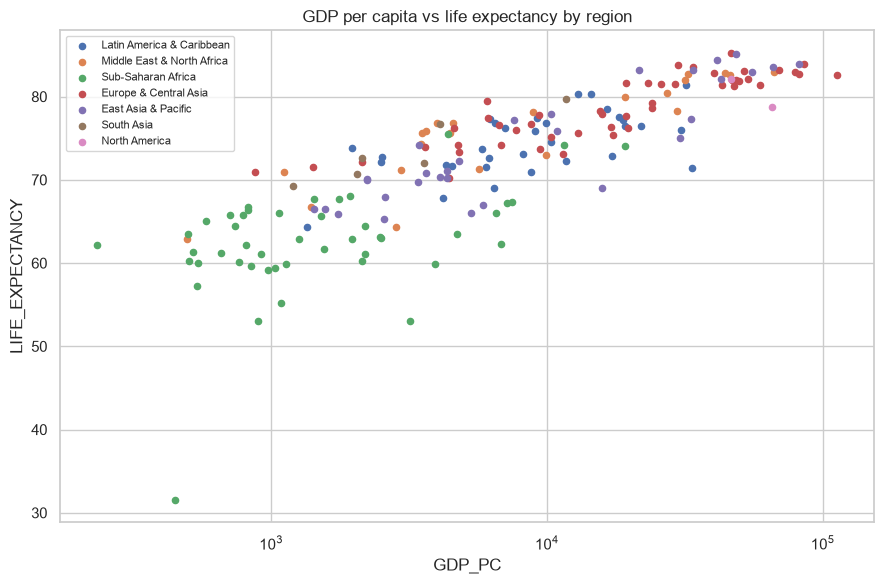

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))
for region in df['region'].unique():
    part = df[df['region'] == region]
    ax.scatter(part['GDP_PC'], part['LIFE_EXPECTANCY'], s=20, label=region)
ax.set_xscale('log')
plt.xlabel('GDP_PC')
plt.ylabel('LIFE_EXPECTANCY')
plt.legend(fontsize=8)
plt.title('GDP per capita vs life expectancy by region')
plt.tight_layout()
plt.savefig('../figures/02_pairwise_region.png', dpi=200)
plt.show()